
# E-commerce Sales and Customer Analysis

## 1. Project Overview

### Business Problem
Retail businesses need to understand their sales performance, identify high-performing products and markets, and analyze customer purchasing behavior to make better decisions.

### Project Objective
Analyze online retail transaction data using Python and SQL to discover sales trends, revenue drivers, and customer purchasing patterns.

### Dataset
Online Retail transaction dataset covering December 2010 to December 2011.

### Tools and Technologies
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- SQLite
- SQL
- Jupyter Notebook

### Expected Outcomes
- Measure overall sales performance.
- Identify top-performing products and countries.
- Examine monthly revenue patterns.
- Analyze repeat customer behavior.
- Provide evidence-based business recommendations.

In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns


## 2. Data Loading and Exploration

This section loads the original retail dataset and examines its structure, data types, and data quality before cleaning.

### 2.1 Load the Dataset
### 2.2 Inspect the Dataset
### 2.3 Check Missing Values
### 2.4 Review Data Types and Summary Statistics

In [ ]:
df=pd.read_excel('Online Retail.xlsx')

In [6]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
df.shape

(541909, 8)

In [8]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [9]:
df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

In [10]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [11]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [12]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

In [13]:
df[["Quantity", "UnitPrice", "Revenue"]].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [14]:
total_revenue = df["Revenue"].sum()

In [15]:
print(f"Total Revenue: {total_revenue:,.2f}")

Total Revenue: 9,747,747.93


In [16]:
total_orders = df["InvoiceNo"].nunique()
print(f"Total Orders: {total_orders:,}")

Total Orders: 25,900


In [17]:
total_customers = df["CustomerID"].nunique()
print(f"Total Customers: {total_customers:,}")

Total Customers: 4,372


In [18]:
average_order_value = total_revenue / total_orders
print(f"Average Order Value: {average_order_value:,.2f}")

Average Order Value: 376.36


In [19]:
#Check cancelled orders
cancelled_orders = df["InvoiceNo"].astype(str).str.startswith("C")
print(f"Cancelled Orders: {cancelled_orders.sum():,}")
print(f"Normal transactions: {len(df) - cancelled_orders.sum():,}")

Cancelled Orders: 9,288
Normal transactions: 532,621


In [20]:
# check for negative quantity and unit price
print(f"Negative Quantity: {(df['Quantity'] < 0).sum():,}")
print(f"Negative Unit Price: {(df['UnitPrice'] < 0).sum():,}")

Negative Quantity: 10,624
Negative Unit Price: 2


In [21]:
#check for zero quantity and zero unit price
print(f"Zero Quantity: {(df['Quantity'] == 0).sum():,}")
print(f"Zero Unit Price: {(df['UnitPrice'] == 0).sum():,}")

Zero Quantity: 0
Zero Unit Price: 2,515



## 3. Data Cleaning and Preparation

The raw dataset was inspected to identify invalid transactions and missing values.

### 3.1 Remove Cancelled Transactions
Invoices marked as cancellations were excluded from the sales analysis.

### 3.2 Remove Invalid Transactions
Transactions with zero or negative quantities and zero or negative unit prices were excluded.

### 3.3 Calculate Revenue
Revenue was calculated by multiplying quantity by unit price.

### 3.4 Prepare Date and Invoice Fields
Invoice dates were converted to datetime format, and invoice numbers were standardized for consistent analysis.

### 3.5 Handle Missing Customer IDs
Missing CustomerIDs were excluded only from customer-level analysis, where customer identification is required.

In [22]:
# create clean dataset for sales analysis
sales_df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0) & (~df["InvoiceNo"].astype(str).str.startswith("C"))].copy()
print("original rows:", len(df))
print("cleaned rows:", len(sales_df))

original rows: 541909
cleaned rows: 530104


In [23]:
# check cleaned data
print("Negative quantities:", (sales_df["Quantity"] < 0).sum())
print("Zero quantities:", (sales_df["Quantity"] == 0).sum())
print("Negative prices:", (sales_df["UnitPrice"] < 0).sum())
print("Zero prices:", (sales_df["UnitPrice"] == 0).sum())
print("Cancelled invoices:", sales_df["InvoiceNo"].astype(str).str.startswith("C").sum())

Negative quantities: 0
Zero quantities: 0
Negative prices: 0
Zero prices: 0
Cancelled invoices: 0


In [24]:
# Calculate revenue after cleaning

sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

total_revenue = sales_df["Revenue"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
total_customers = sales_df["CustomerID"].nunique()
average_order_value = total_revenue / total_orders

print(f"Clean Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

Clean Revenue: £10,666,684.54
Total Orders: 19,960
Total Customers: 4,338
Average Order Value: £534.40


In [25]:
# Convert InvoiceDate to datetime

sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

print(sales_df["InvoiceDate"].min())
print(sales_df["InvoiceDate"].max())

2010-12-01 08:26:00
2011-12-09 12:50:00


## 4. Exploratory Data Analysis (EDA)

This section analyzes the cleaned retail transactions to understand revenue performance, product demand, geographic markets, and monthly sales patterns.

### 4.1 Overall Sales Performance
Calculate total revenue, number of orders, and number of customers.

### 4.2 Monthly Revenue Trend
Examine how revenue changes over time.

### 4.3 Top-Performing Products
Identify products generating the highest revenue.

### 4.4 Country-Wise Revenue
Compare revenue across countries.

### 4.5 Customer Purchasing Patterns
Examine customer contribution and repeat purchasing behavior.

In [26]:
# Create Month column

sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")

monthly_revenue = (
    sales_df.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

monthly_revenue

,Month,Revenue
0,2010-12,823746.140
1,2011-01,691364.560
2,2011-02,523631.890
3,2011-03,717639.360
4,2011-04,537808.621
5,2011-05,770536.020
6,2011-06,761739.900
7,2011-07,719221.191
8,2011-08,759138.380
9,2011-09,1058590.172


In [27]:
monthly_revenue["Month"] = monthly_revenue["Month"].astype(str)

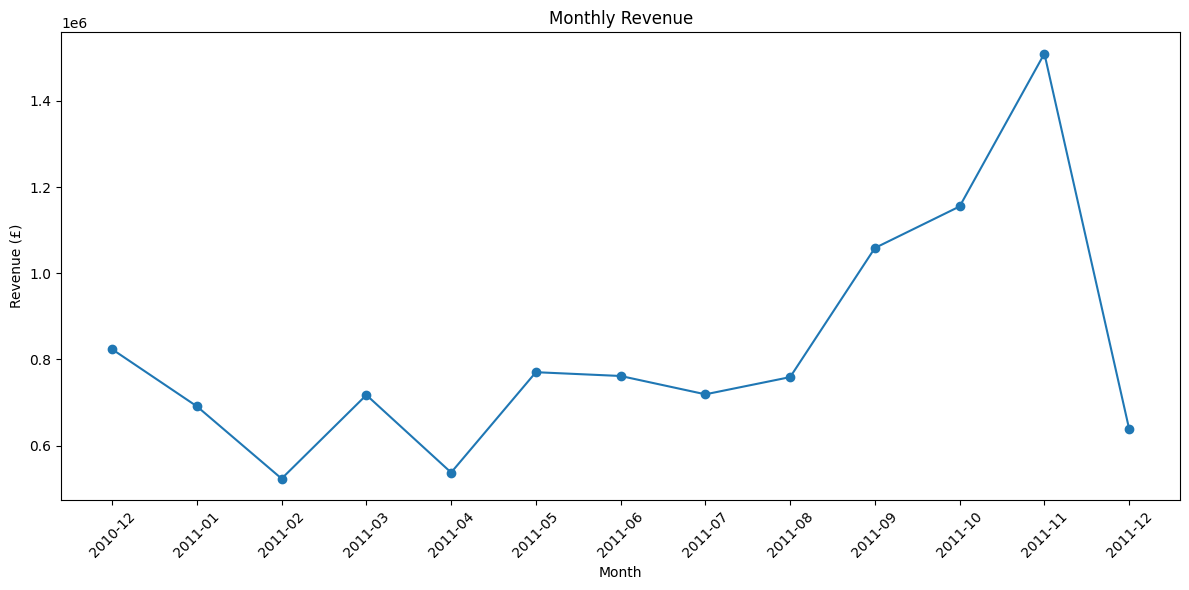

In [28]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue["Month"],
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [29]:
# Top 10 products by revenue
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index())

top_products

,Description,Revenue
0,DOTCOM POSTAGE,206248.77
1,REGENCY CAKESTAND 3 TIER,174484.74
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,WHITE HANGING HEART T-LIGHT HOLDER,106292.77
4,PARTY BUNTING,99504.33
5,JUMBO BAG RED RETROSPOT,94340.05
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,Manual,78112.82
8,POSTAGE,78101.88
9,RABBIT NIGHT LIGHT,66964.99


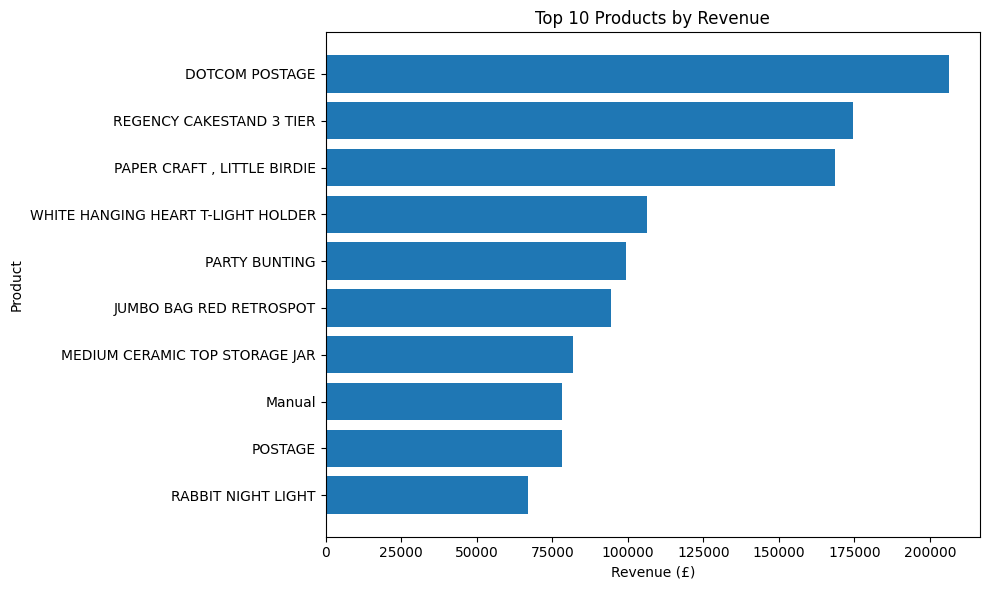

In [30]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_products["Description"][::-1],
    top_products["Revenue"][::-1]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [31]:
top_10_revenue = top_products["Revenue"].sum()
total_revenue = sales_df["Revenue"].sum()

percentage = (top_10_revenue / total_revenue) * 100

print(f"Top 10 products revenue: £{top_10_revenue:,.2f}")
print(f"Percentage of total revenue: {percentage:.2f}%")

Top 10 products revenue: £1,154,220.87
Percentage of total revenue: 10.82%


In [32]:
# Revenue by country
country_revenue = (sales_df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).reset_index())
country_revenue.head(10)

,Country,Revenue
0,United Kingdom,9025222.084
1,Netherlands,285446.340
2,EIRE,283453.960
3,Germany,228867.140
4,France,209715.110
5,Australia,138521.310
6,Spain,61577.110
7,Switzerland,57089.900
8,Belgium,41196.340
9,Sweden,38378.330


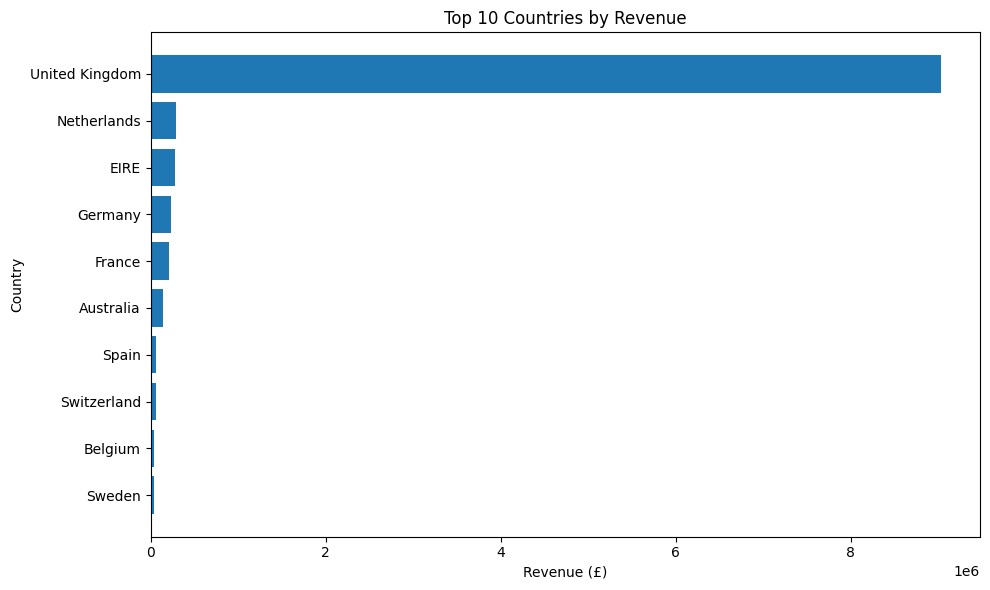

In [33]:
# Visualise Revenue by country

top_countries = country_revenue.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries["Country"][::-1],
    top_countries["Revenue"][::-1]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [34]:
# Revenue contribution of top 5 countries

top_5_country_revenue = country_revenue.head(5)["Revenue"].sum()

percentage = (top_5_country_revenue / total_revenue) * 100

print(f"Top 5 countries revenue: £{top_5_country_revenue:,.2f}")
print(f"Top 5 countries contribution: {percentage:.2f}%")

Top 5 countries revenue: £10,032,704.63
Top 5 countries contribution: 94.06%


In [35]:
# Keep only transactions with a known CustomerID

customer_df = sales_df.dropna(subset=["CustomerID"]).copy()

print("Customer analysis rows:", len(customer_df))
print("Unique customers:", customer_df["CustomerID"].nunique())

Customer analysis rows: 397884
Unique customers: 4338


In [36]:
# Top 10 customers by revenue

top_customers = (
    customer_df.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_customers

,CustomerID,Revenue
0,14646.0,280206.02
1,18102.0,259657.30
2,17450.0,194550.79
3,16446.0,168472.50
4,14911.0,143825.06
5,12415.0,124914.53
6,14156.0,117379.63
7,17511.0,91062.38
8,16029.0,81024.84
9,12346.0,77183.60


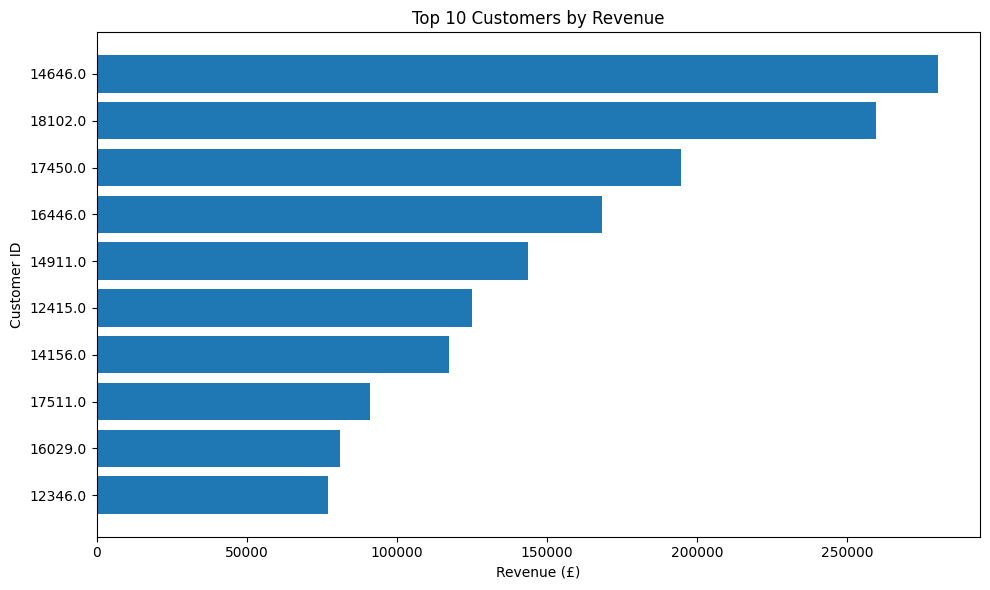

In [37]:
# visualise Top 10 Customers by Revenue
plt.figure(figsize=(10, 6))

plt.barh(
    top_customers["CustomerID"].astype(str)[::-1],
    top_customers["Revenue"][::-1]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [38]:
# Calculate the number of orders per customer
customer_orders = (
    customer_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="OrderCount")
)

customer_orders.head(10)

,CustomerID,OrderCount
0,12748.0,209
1,14911.0,201
2,17841.0,124
3,13089.0,97
4,14606.0,93
5,15311.0,91
6,12971.0,86
7,14646.0,73
8,16029.0,63
9,13408.0,62


In [39]:
# Calculate the number of repeat customers (customers with more than 1 order)
repeat_customers = customer_orders[
    customer_orders["OrderCount"] > 1
]

total_known_customers = customer_orders["CustomerID"].nunique()
repeat_customer_count = repeat_customers["CustomerID"].nunique()

repeat_percentage = (
    repeat_customer_count / total_known_customers
) * 100

print(f"Customers with more than 1 order: {repeat_customer_count:,}")
print(f"Total customers analyzed: {total_known_customers:,}")
print(f"Repeat customer percentage: {repeat_percentage:.2f}%")

Customers with more than 1 order: 2,845
Total customers analyzed: 4,338
Repeat customer percentage: 65.58%



## 5. SQL Business Analysis

SQLite was used to query the cleaned transaction data and answer key business questions.

### 5.1 Overall Sales Performance
Calculate total revenue and the number of unique orders.

### 5.2 Top 10 Products by Revenue
Identify the products generating the highest revenue.

### 5.3 Country-Wise Sales Performance
Compare sales across countries to identify important markets.

### 5.4 Monthly Revenue Analysis
Summarize revenue by month and compare sales performance over time.

In [40]:
import sqlite3
conn = sqlite3.connect("ecommerce_analysis.db")

In [41]:
print(sales_df.dtypes)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
Revenue               float64
Month               period[M]
dtype: object


In [42]:
sales_df["Revenue"] = pd.to_numeric(
    sales_df["Revenue"],
    errors="coerce"
)

sales_df["Quantity"] = pd.to_numeric(
    sales_df["Quantity"],
    errors="coerce"
)

sales_df["UnitPrice"] = pd.to_numeric(
    sales_df["UnitPrice"],
    errors="coerce"
)

sales_df["CustomerID"] = pd.to_numeric(
    sales_df["CustomerID"],
    errors="coerce"
)

sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"],
    errors="coerce"
)

In [43]:
sales_df["InvoiceDate"] = sales_df["InvoiceDate"].dt.strftime(
    "%Y-%m-%d %H:%M:%S"
)

In [44]:
conn.close()

In [45]:
conn = sqlite3.connect("ecommerce_analysis.db")

In [46]:
print(sales_df.dtypes)
print(sales_df.iloc[:, 8].head())
print(type(sales_df.iloc[0, 8]))

InvoiceNo         object
StockCode         object
Description       object
Quantity           int64
InvoiceDate       object
UnitPrice        float64
CustomerID       float64
Country           object
Revenue          float64
Month          period[M]
dtype: object
0    15.30
1    20.34
2    22.00
3    20.34
4    20.34
Name: Revenue, dtype: float64
<class 'numpy.float64'>


In [47]:
print("Rows:", len(sales_df))
print("Columns:", sales_df.shape[1])
print(sales_df.head())

Rows: 530104
Columns: 10
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           InvoiceDate  UnitPrice  CustomerID         Country  Revenue  \
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30   
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34   
2  2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00   
3  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34   
4  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34   

     Month  
0  2010-12  
1  2010-12  
2  2010-12  
3  2010-12  
4  2010-12  


In [48]:
print(sales_df["Revenue"].describe())

count    530104.000000
mean         20.121871
std         270.356743
min           0.001000
25%           3.750000
50%           9.900000
75%          17.700000
max      168469.600000
Name: Revenue, dtype: float64


In [49]:
sales_df = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"]
)

sales_df["Month"] = (
    sales_df["InvoiceDate"].dt.to_period("M").astype(str)
)
sales_df["InvoiceNo"] = sales_df["InvoiceNo"].astype(str).str.strip()

In [50]:
print("Rows:", len(sales_df))
print("Columns:", sales_df.shape[1])
print(sales_df.head())

Rows: 530104
Columns: 10
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Revenue    Month  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  2010-12  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  2010-12  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  2010-12  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  2010-12  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  2010-12  


In [51]:
import sqlite3

conn = sqlite3.connect("ecommerce_analysis.db")

sales_df.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("SQL table created successfully!")

SQL table created successfully!


In [52]:
result = pd.read_sql_query(
    "SELECT COUNT(*) AS row_count FROM sales;",
    conn
)

print(result)

   row_count
0     530104


In [53]:
result = pd.read_sql_query(
    "SELECT * FROM sales LIMIT 5;",
    conn
)
print(result.to_string())

  InvoiceNo StockCode                          Description  Quantity          InvoiceDate  UnitPrice  CustomerID         Country  Revenue    Month
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6  2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  2010-12
1    536365     71053                  WHITE METAL LANTERN         6  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  2010-12
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8  2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  2010-12
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  2010-12
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  2010-12


In [54]:
query = """
SELECT ROUND(SUM(Revenue), 2) AS total_revenue
FROM sales;
"""

print(pd.read_sql_query(query, conn))

   total_revenue
0    10666684.54


In [55]:
query = """
SELECT
    Description,
    ROUND(SUM(Revenue), 2) AS total_revenue
FROM sales
WHERE Description IS NOT NULL
GROUP BY Description
ORDER BY total_revenue DESC
LIMIT 10;
"""

top_products_sql = pd.read_sql_query(query, conn)
print(top_products_sql.to_string(index=False))

                       Description  total_revenue
                    DOTCOM POSTAGE      206248.77
          REGENCY CAKESTAND 3 TIER      174484.74
       PAPER CRAFT , LITTLE BIRDIE      168469.60
WHITE HANGING HEART T-LIGHT HOLDER      106292.77
                     PARTY BUNTING       99504.33
           JUMBO BAG RED RETROSPOT       94340.05
    MEDIUM CERAMIC TOP STORAGE JAR       81700.92
                            Manual       78112.82
                           POSTAGE       78101.88
                RABBIT NIGHT LIGHT       66964.99


In [56]:
query = """
SELECT
    Country,
    ROUND(SUM(Revenue), 2) AS total_revenue
FROM sales
GROUP BY Country
ORDER BY total_revenue DESC
LIMIT 10;
"""

top_countries_sql = pd.read_sql_query(query, conn)
print(top_countries_sql.to_string(index=False))

       Country  total_revenue
United Kingdom     9025222.08
   Netherlands      285446.34
          EIRE      283453.96
       Germany      228867.14
        France      209715.11
     Australia      138521.31
         Spain       61577.11
   Switzerland       57089.90
       Belgium       41196.34
        Sweden       38378.33


In [57]:
sales_df.to_csv("sales_cleaned.csv", index=False)

print("CSV file created successfully!")

CSV file created successfully!


In [58]:
# Export the cleaned dataset
sales_df.to_csv("sales_cleaned.csv", index=False)

# Check the exported data
print("Rows:", len(sales_df))
print("Columns:", sales_df.columns.tolist())
print("Missing invoice numbers:", sales_df["InvoiceNo"].isna().sum())
print("Total revenue: £", round(sales_df["Revenue"].sum(), 2))

Rows: 530104
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'Month']
Missing invoice numbers: 0
Total revenue: £ 10666684.54


In [60]:
top10_revenue = sales_df.groupby("Description")["Revenue"].sum().nlargest(10).sum()
total_revenue = sales_df["Revenue"].sum()

print("Top 10 products' revenue share:",
      round(top10_revenue / total_revenue * 100, 2), "%")

Top 10 products' revenue share: 10.82 %


In [61]:
customer_orders = customer_df.groupby("CustomerID")["InvoiceNo"].nunique()

repeat_percent = (customer_orders >= 2).sum() / len(customer_orders) * 100

print("Repeat customers:",
      round(repeat_percent, 2), "%")

Repeat customers: 65.58 %


In [59]:
import sqlite3
import pandas as pd

# Connect to your existing database
conn = sqlite3.connect("ecommerce_analysis.db")

# Replace the old sales table with the updated data
sales_df.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

# Verify the updated table
result = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS total_rows,
        ROUND(SUM(Revenue), 2) AS total_revenue,
        COUNT(DISTINCT InvoiceNo) AS total_orders
    FROM sales
    """,
    conn
)

display(result)
conn.close()

,total_rows,total_revenue,total_orders
0,530104,10666684.54,19960



## 6. Key Findings and Business Recommendations

### 6.1 Key Findings

- **Product performance:** The top 10 products account for approximately 10.82% of cleaned revenue, based on the current analysis.
- **Customer behavior:** Repeat customers represent approximately 65.58% of customers with known CustomerIDs, based on the current analysis.
- **Sales performance:** Monthly and country-level revenue analysis helps identify changes in sales and important markets.

### 6.2 Business Recommendations

- **Product strategy:** Monitor high-revenue products and ensure adequate inventory for products with sustained demand.
- **Customer retention:** Study repeat customers' purchasing patterns and consider targeted loyalty offers.
- **Market strategy:** Compare country-level revenue and investigate opportunities in markets with strong sales.
- **Sales monitoring:** Track monthly revenue to identify unusual changes and support business planning.

### 6.3 Limitations

- The dataset covers transactions from 2010–2011 and may not represent current retail behavior.
- Customer-level analysis excludes transactions with missing CustomerIDs.
- Revenue is calculated from quantity multiplied by unit price; it should not automatically be interpreted as profit.